# CatBoost: диагностика выбранной пары

Методика – оценка бинарной классификации GoA по сохраненным прогнозам.
Обучения и подбора параметров в этом ноутбуке нет. Пороги зафиксированы по
validation. Test уже просмотрен в предыдущем исследовании, поэтому сравнение
семейств имеет исследовательский статус. Результаты не подтверждают готовность
к эксплуатации. AP зависит от распространенности GoA; важность признака
не является причинным эффектом погоды.


In [1]:
from pathlib import Path
import json,sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from catboost import CatBoostClassifier
from sklearn.metrics import precision_recall_curve
ROOT=Path.cwd();BASE=ROOT/'research/boosting-weather-comparison';DEST=ROOT/'artifacts/boosting-weather-comparison'
sys.path.insert(0,str(ROOT/'src'))
from approach_risk.evaluation.classification import metrics
plt.rcParams.update({'figure.dpi':120,'font.size':10})
pred={name:pd.read_parquet(DEST/f'{name}_test_predictions.parquet') for name in ['baseline','weather']}
assert pred['baseline'].drop(columns='probability').equals(pred['weather'].drop(columns='probability'))
selection=json.loads((BASE/'reports/02_selection.json').read_text(encoding='utf8'))
evaluation=pd.read_csv(BASE/'reports/03_test_evaluation.csv')
display(pd.read_csv(BASE/'reports/01_validation_candidates.csv')[['variant','candidate','depth','learning_rate','AP','ROC_AUC','Brier']])
display(selection)
def save(fig,name):
    for ext in ['png','svg']:
        path=BASE/f'figures/{name}.{ext}'
        fig.savefig(path,dpi=160,bbox_inches='tight')
        if ext=='svg':path.write_text('\n'.join(line.rstrip() for line in path.read_text(encoding='utf8').splitlines())+'\n',encoding='utf8')


,variant,candidate,depth,learning_rate,AP,ROC_AUC,Brier
0,baseline,fixed,6,0.05,0.004478,0.598169,0.003066
1,baseline,d4_lr0.03,4,0.03,0.004191,0.590406,0.003067
2,baseline,d4_lr0.1,4,0.10,0.004595,0.596237,0.003066
3,baseline,d8_lr0.03,8,0.03,0.004365,0.596279,0.003066
4,baseline,d8_lr0.1,8,0.10,0.004713,0.592798,0.003066
5,weather,fixed,6,0.05,0.008368,0.645041,0.003062
6,weather,d4_lr0.03,4,0.03,0.008549,0.637842,0.003061
7,weather,d4_lr0.1,4,0.10,0.008772,0.646435,0.003061
8,weather,d8_lr0.03,8,0.03,0.008394,0.644545,0.003062
9,weather,d8_lr0.1,8,0.10,0.008258,0.651496,0.003062


{'fingerprint': 'ca87eaf6b653ff7b87f424efa75cfba7e4baddc847d338681b468d72470380ea',
 'criterion': 'validation AP, then smaller depth, then learning rate',
 'selected': {'baseline': 'd8_lr0.1', 'weather': 'd4_lr0.1'},
 'test_used_for_selection': False}

## Precision–recall на test

Пунктирная линия показывает долю GoA. Левый график показывает весь диапазон,
правый – первые 20% полноты. График не служит для выбора рабочего порога.


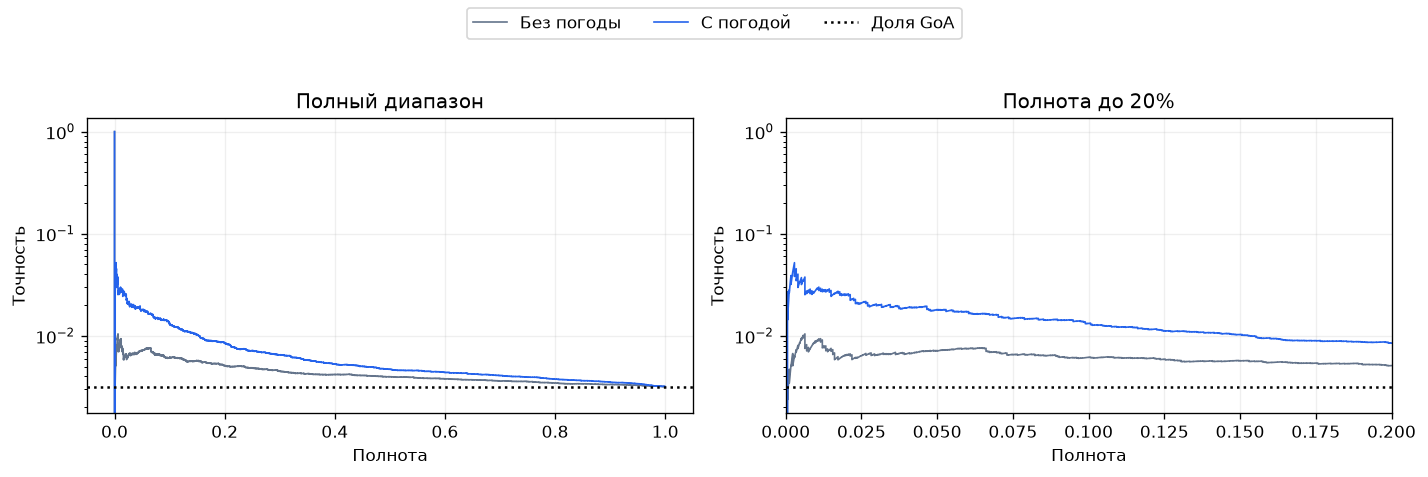

In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,label,color in [('baseline','Без погоды','#64748b'),('weather','С погодой','#2563eb')]:
    f=pred[name];precision,recall,_=precision_recall_curve(f.GoA,f.probability)
    for ax in axes:ax.plot(recall,precision,label=label,color=color,linewidth=1)
for ax in axes:
    ax.axhline(pred['baseline'].GoA.mean(),color='black',linestyle=':',label='Доля GoA')
    ax.set_xlabel('Полнота');ax.set_ylabel('Точность');ax.set_yscale('log');ax.grid(alpha=.2)
axes[0].set_title('Полный диапазон');axes[1].set_title('Полнота до 20%');axes[1].set_xlim(0,.2)
handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='upper center',ncol=3)
fig.tight_layout(rect=(0,0,1,.85));save(fig,'04_precision_recall');plt.show()


## Калибровка

Используем десять групп приблизительно одинакового размера по оценке риска.
Показываем средний прогноз и фактическую долю GoA, а также число наблюдений
и событий. Это описательная проверка; калибратор по test не обучаем.


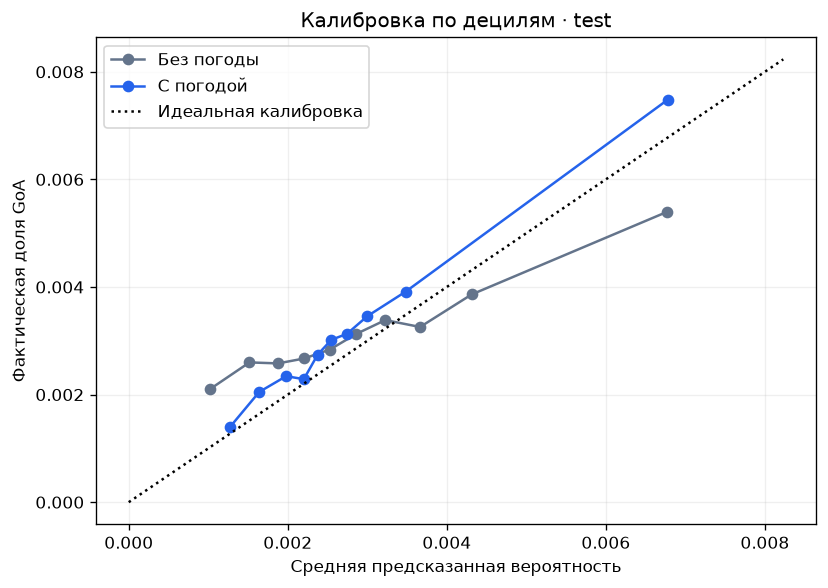

,bin,n,events,predicted,observed,variant
0,"(-0.0009718, 0.00131]",54658,115,0.001024,0.002104,baseline
1,"(0.00131, 0.00171]",54658,142,0.001518,0.002598,baseline
2,"(0.00171, 0.00204]",54657,141,0.001877,0.002580,baseline
3,"(0.00204, 0.00237]",54658,146,0.002207,0.002671,baseline
4,"(0.00237, 0.00269]",54658,155,0.002528,0.002836,baseline
5,"(0.00269, 0.00304]",54657,171,0.002863,0.003129,baseline
6,"(0.00304, 0.00343]",54658,185,0.003227,0.003385,baseline
7,"(0.00343, 0.00393]",54657,178,0.003664,0.003257,baseline
8,"(0.00393, 0.00481]",54658,211,0.004311,0.003860,baseline
9,"(0.00481, 0.132]",54658,295,0.006771,0.005397,baseline


In [3]:
fig,ax=plt.subplots(figsize=(7,5));tables=[]
for name,label,color in [('baseline','Без погоды','#64748b'),('weather','С погодой','#2563eb')]:
    f=pred[name].copy();f['bin']=pd.qcut(f.probability,10,duplicates='drop')
    table=f.groupby('bin',observed=True).agg(n=('GoA','size'),events=('GoA','sum'),predicted=('probability','mean'),observed=('GoA','mean')).reset_index()
    table['bin']=table['bin'].astype(str);table['variant']=name;tables.append(table)
    ax.plot(table.predicted,table.observed,'o-',label=label,color=color)
limit=max(t[['predicted','observed']].to_numpy().max() for t in tables)*1.1
ax.plot([0,limit],[0,limit],':',color='black',label='Идеальная калибровка')
ax.set(xlabel='Средняя предсказанная вероятность',ylabel='Фактическая доля GoA',title='Калибровка по децилям · test')
ax.legend(loc='best');ax.grid(alpha=.2);fig.tight_layout();save(fig,'05_calibration');plt.show()
calibration=pd.concat(tables,ignore_index=True);calibration.to_csv(BASE/'reports/07_calibration_deciles.csv',index=False);display(calibration)


## Перенос порогов validation → test

Для каждого заданного ограничения FPR порог выбирается только на validation.
На test отдельно считаем фактический FPR, полноту, точность, TP и FP.
Одинаковое ограничение при выборе не гарантирует одинаковый FPR в новом периоде.


,variant,validation_FPR_budget,threshold,test_recall,test_FPR,test_precision,TP,FP
0,baseline,0.001,0.014443,0.006325,0.002531,0.007914,11,1379
1,baseline,0.005,0.009018,0.021852,0.011312,0.006128,38,6163
2,baseline,0.010,0.007402,0.050029,0.022186,0.007146,87,12088
3,weather,0.001,0.024338,0.008626,0.001037,0.025862,15,565
4,weather,0.005,0.012535,0.037378,0.006339,0.018471,65,3454
5,weather,0.010,0.009720,0.067280,0.013123,0.016100,117,7150


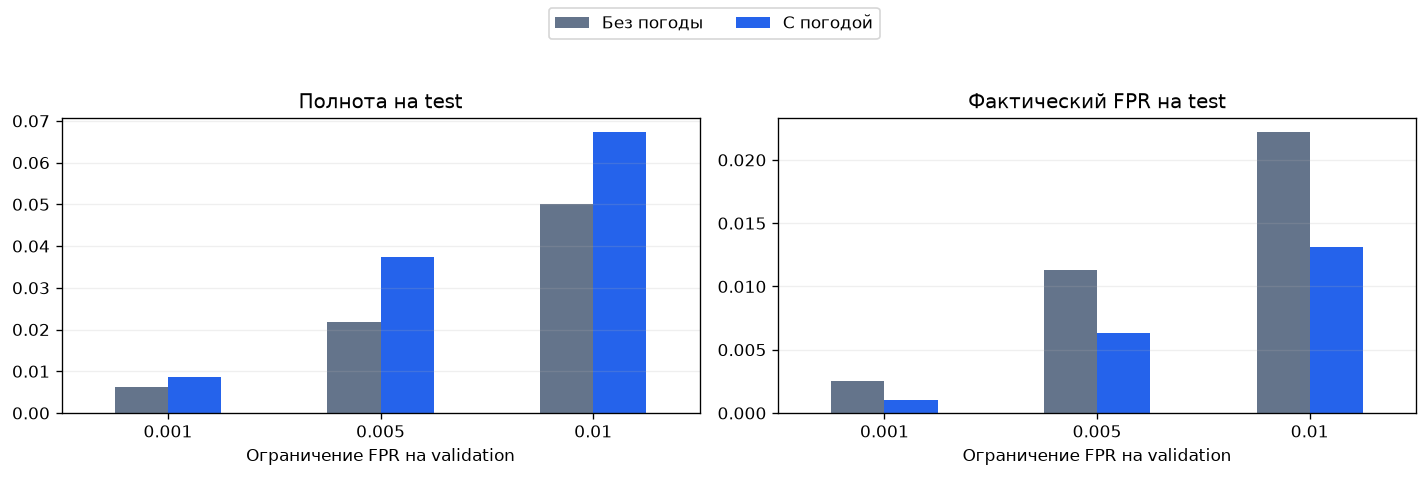

In [4]:
thresholds=json.loads((BASE/'reports/03_thresholds.json').read_text(encoding='utf8'));rows=[]
for name,f in pred.items():
    for budget,threshold in thresholds[name].items():
        alarm=f.probability>=threshold;y=f.GoA.astype(bool)
        tp=int((alarm&y).sum());fp=int((alarm&~y).sum())
        rows.append({'variant':name,'validation_FPR_budget':float(budget),'threshold':threshold,'test_recall':tp/y.sum(),'test_FPR':fp/(~y).sum(),'test_precision':tp/(tp+fp) if tp+fp else np.nan,'TP':tp,'FP':fp})
operating=pd.DataFrame(rows);operating.to_csv(BASE/'reports/07_operating_points.csv',index=False);display(operating)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,title in zip(axes,['test_recall','test_FPR'],['Полнота на test','Фактический FPR на test']):
    operating.pivot(index='validation_FPR_budget',columns='variant',values=metric).plot.bar(ax=ax,rot=0,color=['#64748b','#2563eb'])
    ax.set_title(title);ax.set_xlabel('Ограничение FPR на validation');ax.get_legend().remove();ax.grid(axis='y',alpha=.2)
handles,_=axes[0].get_legend_handles_labels();fig.legend(handles,['Без погоды','С погодой'],loc='upper center',ncol=2)
fig.tight_layout(rect=(0,0,1,.85));save(fig,'06_operating_points');plt.show()


## Срезы по аэропортам, месяцам и покрытию погоды

Это описательные срезы заранее определенных групп. Показываем объем и число
GoA, чтобы не сравнивать только точечные метрики при разном числе событий.
Поиск лучшего аэропорта или месяца по test не является валидацией модели.


,dimension,group,model,rows,GoA,AP,ROC_AUC,Brier,target_validation_FPR,TP,FP,FN,TN,recall,FPR,precision
8,airport,EDDB,baseline,20511,75,0.004140,0.509240,0.003645,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,airport,EDDB,baseline,20511,75,NaN,NaN,NaN,0.001,0.0,0.0,75.0,20436.0,0.000000,0.000000,NaN
10,airport,EDDB,baseline,20511,75,NaN,NaN,NaN,0.005,0.0,17.0,75.0,20419.0,0.000000,0.000832,0.000000
11,airport,EDDB,baseline,20511,75,NaN,NaN,NaN,0.010,0.0,64.0,75.0,20372.0,0.000000,0.003132,0.000000
12,airport,EDDB,weather,20511,75,0.008727,0.628323,0.003640,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147,airport,LSZH,baseline,33461,131,NaN,NaN,NaN,0.010,10.0,1300.0,121.0,32030.0,0.076336,0.039004,0.007634
148,airport,LSZH,weather,33461,131,0.010552,0.666518,0.003893,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
149,airport,LSZH,weather,33461,131,NaN,NaN,NaN,0.001,2.0,16.0,129.0,33314.0,0.015267,0.000480,0.111111
150,airport,LSZH,weather,33461,131,NaN,NaN,NaN,0.005,3.0,92.0,128.0,33238.0,0.022901,0.002760,0.031579


,dimension,group,model,rows,GoA,AP,ROC_AUC,Brier,target_validation_FPR,TP,FP,FN,TN,recall,FPR,precision
152,period,2023-01,baseline,121919,414,0.005636,0.582282,0.003383,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
153,period,2023-01,baseline,121919,414,NaN,NaN,NaN,0.001,2.0,117.0,412.0,121388.0,0.004831,0.000963,0.016807
154,period,2023-01,baseline,121919,414,NaN,NaN,NaN,0.005,9.0,975.0,405.0,120530.0,0.021739,0.008024,0.009146
155,period,2023-01,baseline,121919,414,NaN,NaN,NaN,0.010,30.0,2259.0,384.0,119246.0,0.072464,0.018592,0.013106
156,period,2023-01,weather,121919,414,0.008817,0.644387,0.003380,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
157,period,2023-01,weather,121919,414,NaN,NaN,NaN,0.001,6.0,160.0,408.0,121345.0,0.014493,0.001317,0.036145
158,period,2023-01,weather,121919,414,NaN,NaN,NaN,0.005,25.0,1093.0,389.0,120412.0,0.060386,0.008996,0.022361
159,period,2023-01,weather,121919,414,NaN,NaN,NaN,0.010,47.0,2557.0,367.0,118948.0,0.113527,0.021044,0.018049
160,period,2023-02,baseline,87198,244,0.003267,0.551551,0.002798,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
161,period,2023-02,baseline,87198,244,NaN,NaN,NaN,0.001,4.0,1073.0,240.0,85881.0,0.016393,0.012340,0.003714


,dimension,group,model,rows,GoA,AP,ROC_AUC,Brier,target_validation_FPR,TP,FP,FN,TN,recall,FPR,precision
192,weather_coverage,False,baseline,539,0,NaN,NaN,0.000010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
193,weather_coverage,False,baseline,539,0,NaN,NaN,NaN,0.001,0.0,0.0,0.0,539.0,NaN,0.000000,NaN
194,weather_coverage,False,baseline,539,0,NaN,NaN,NaN,0.005,0.0,1.0,0.0,538.0,NaN,0.001855,0.000000
195,weather_coverage,False,baseline,539,0,NaN,NaN,NaN,0.010,0.0,7.0,0.0,532.0,NaN,0.012987,0.000000
196,weather_coverage,False,weather,539,0,NaN,NaN,0.000015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
197,weather_coverage,False,weather,539,0,NaN,NaN,NaN,0.001,0.0,0.0,0.0,539.0,NaN,0.000000,NaN
198,weather_coverage,False,weather,539,0,NaN,NaN,NaN,0.005,0.0,0.0,0.0,539.0,NaN,0.000000,NaN
199,weather_coverage,False,weather,539,0,NaN,NaN,NaN,0.010,0.0,1.0,0.0,538.0,NaN,0.001855,0.000000
200,weather_coverage,True,baseline,546038,1739,0.004364,0.571099,0.003175,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
201,weather_coverage,True,baseline,546038,1739,NaN,NaN,NaN,0.001,11.0,1379.0,1728.0,542920.0,0.006325,0.002534,0.007914


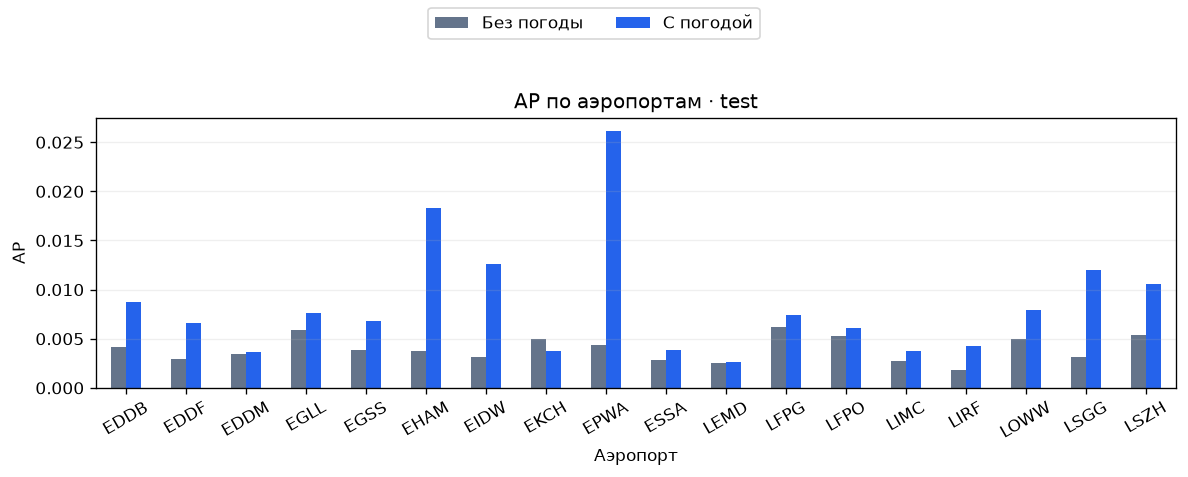

In [5]:
for dimension in ['airport','period','weather_coverage']:
    display(evaluation[evaluation.dimension==dimension])
airport=evaluation[(evaluation.dimension=='airport') & evaluation.AP.notna()]
fig,ax=plt.subplots(figsize=(10,4))
airport.pivot(index='group',columns='model',values='AP').plot.bar(ax=ax,rot=30,color=['#64748b','#2563eb'])
ax.set(title='AP по аэропортам · test',xlabel='Аэропорт',ylabel='AP');ax.grid(axis='y',alpha=.2)
handles,_=ax.get_legend_handles_labels();ax.get_legend().remove();fig.legend(handles,['Без погоды','С погодой'],loc='upper center',ncol=2)
fig.tight_layout(rect=(0,0,1,.85));save(fig,'08_airport_AP');plt.show()


## Важности признаков и ограничения интерпретации

Важности CatBoost относятся к конкретной обученной модели и ее набору
признаков. Коррелирующие признаки могут делить важность. Ни ранжирование,
ни прирост AP не доказывают причинность; прогноз может отражать аэропорт,
сезон, покрытие METAR и другие зависимости.


,feature,importance
1,C40_CROSS_LAT,17.249508
2,C40_CROSS_LON,14.685857
7,day_of_year_cos,14.424541
6,day_of_year_sin,13.940545
4,hour_utc_sin,11.786447
5,hour_utc_cos,11.503958
3,typecode,9.586539
0,airport,6.822605


,feature,importance
1,C40_CROSS_LAT,24.282863
13,visibility_m_model,7.963348
9,wind_gust_kt_model,7.382483
2,C40_CROSS_LON,7.285410
8,wind_speed_kt_model,6.939842
22,gust_group_reported_model,5.777658
0,airport,4.813858
17,temperature_c_model,4.380611
10,wind_direction_deg_model,3.637960
3,typecode,3.416553


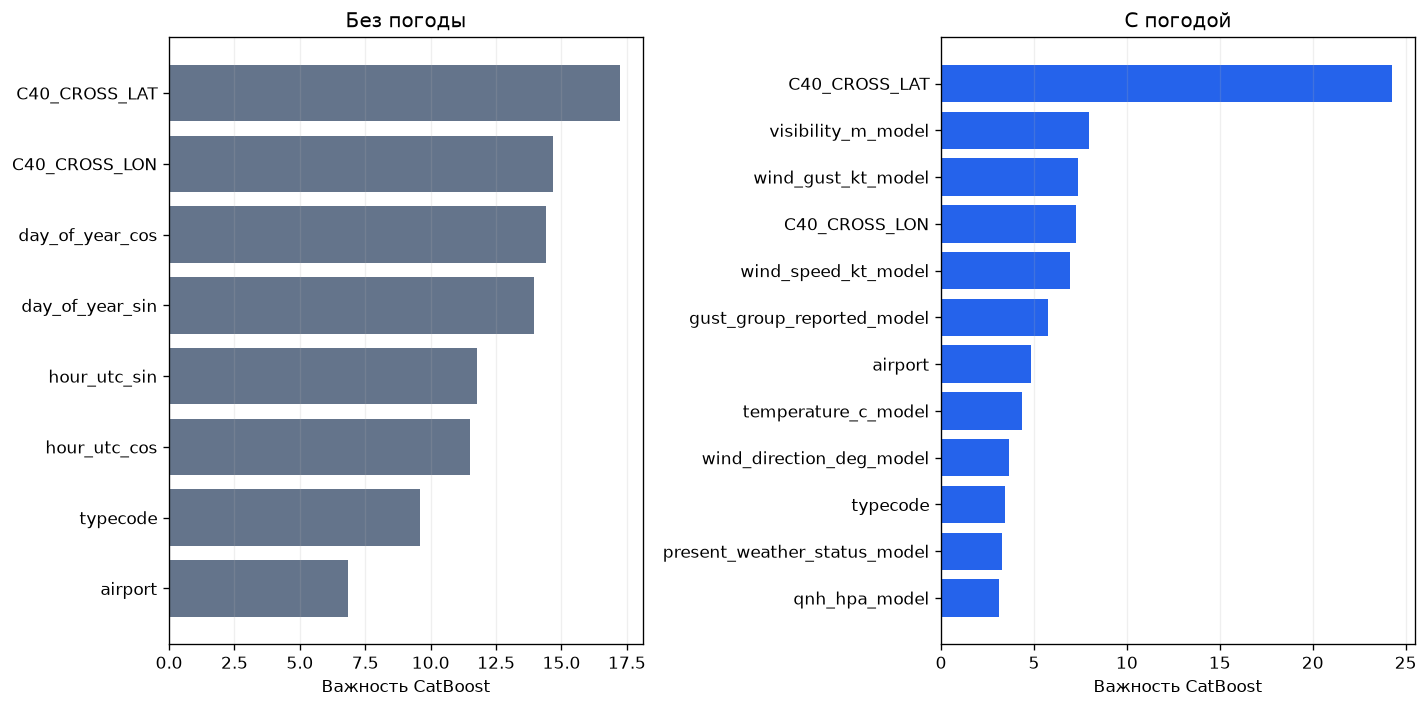

,metric,difference,lower_95,upper_95
0,AP,0.002451,0.001304,0.003992
1,ROC_AUC,0.052536,0.032931,0.073599
2,Brier,-0.000004,-0.000006,-0.000002


In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,6))
for ax,name,title in zip(axes,['baseline','weather'],['Без погоды','С погодой']):
    model=CatBoostClassifier();model.load_model(str(DEST/name/selection['selected'][name]/'model.cbm'))
    values=model.get_feature_importance(type='PredictionValuesChange')
    assert len(values)==len(model.feature_names_) and np.isfinite(values).all() and values.sum()>0
    full=pd.DataFrame({'feature':model.feature_names_,'importance':values})
    full.to_csv(BASE/f'reports/03_{name}_importance.csv',index=False)
    display(full.sort_values('importance',ascending=False))
    importance=full.nlargest(12,'importance').sort_values('importance')
    ax.barh(importance.feature,importance.importance,color='#64748b' if name=='baseline' else '#2563eb')
    ax.set_title(title);ax.set_xlabel('Важность CatBoost');ax.grid(axis='x',alpha=.2)
fig.tight_layout();save(fig,'07_feature_importance');plt.show()
display(pd.read_csv(BASE/'reports/04_day_intervals.csv'))
